# Revisar las curvas de luz sin emparejar buscando eclipses

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits

In [25]:
# Objetos que podrián presentar eclipses: ASASSN -13cx, IP Peg, V363 Lyr y V* V344 Lyr.
ASASSN = "datos_crudos_ztf/raw_ASASSN_-13cx.csv"
NSV = 'datos_crudos_ztf/raw_NSV__4618.csv'
GY = 'datos_crudos_ztf/raw_V*_GY_Hya.csv'

df = pd.read_csv('DN_seleccionadas.csv') 

# Phase Folding


**Do a phase folding in the raw light curves g to watch effectively if the systems have eclipses**

#### ASASSN -13cx

In [119]:
# Buscar informacion de V344 Lyr, separar la zona encima de el quisecense de este sistema con una mascara y verlo en el diagrama H-R.

def magnitudes(objeto, nombre, item):
    dato = pd.read_csv(objeto)
    zg = dato[dato['filtercode'] == 'zg']
    magzg = zg['mag']
    mjdzg = zg['mjd']

    zr = dato[dato['filtercode'] == 'zr']
    magzr = zr['mag']
    mjdzr = zr['mjd']

    df_m =  df[df['Name'] == nombre]
    d = df_m['Parallax'][item]

    mag_g = magzg - 5*np.log10(1000/d) + 5 
    mag_r = magzr - 5*np.log10(1000/d) + 5

    return(mag_g, mag_r, mjdzg, mjdzr)

def phase_folding(P_orb, mag_g, mag_r, time_g, time_r):
    t_g = time_g.values
    m_g = mag_g.values

    t_r = time_r.values
    m_r = mag_r.values

    T0_g = t_g[0]
    T0_r = t_r[0]

    phase_g = ((t_g - T0_g) / P_orb) % 1
    phase_r = ((t_r - T0_r) / P_orb) % 1
    
    # Ordenar por fase
    idx_g = phase_g
    phase_g = phase_g#[idx_g]
    m_g = m_g#[idx_g]

    idx_r = (phase_r)
    phase_r = phase_r#[idx_r]
    m_r = m_r#[idx_r]

    # Plot
    plt.figure(figsize=(10,6))
    plt.scatter(phase_g, m_g, s=10, label = 'g band')
    plt.scatter(phase_r, m_r, s=10, label = 'r band')

    plt.gca().invert_yaxis()
    plt.xlabel("Orbital phase")
    plt.ylabel("Magnitude")
    plt.legend(loc = 'upper right')

    plt.savefig('phase_folding.png', dpi=300,bbox_inches='tight')
    

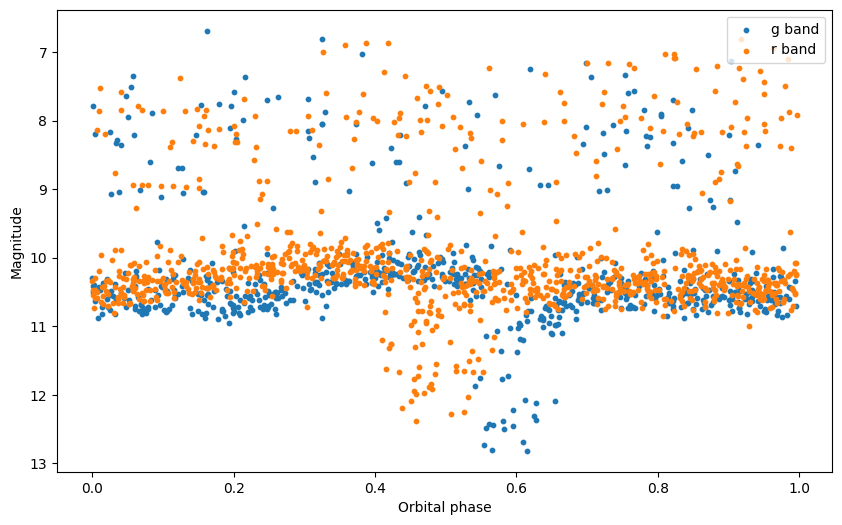

In [120]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_ASASSN_-13cx.csv', 'ASASSN -13cx', 3)
phase_folding(0.07965, mag_g, mag_r, mjd_g, mjd_r)

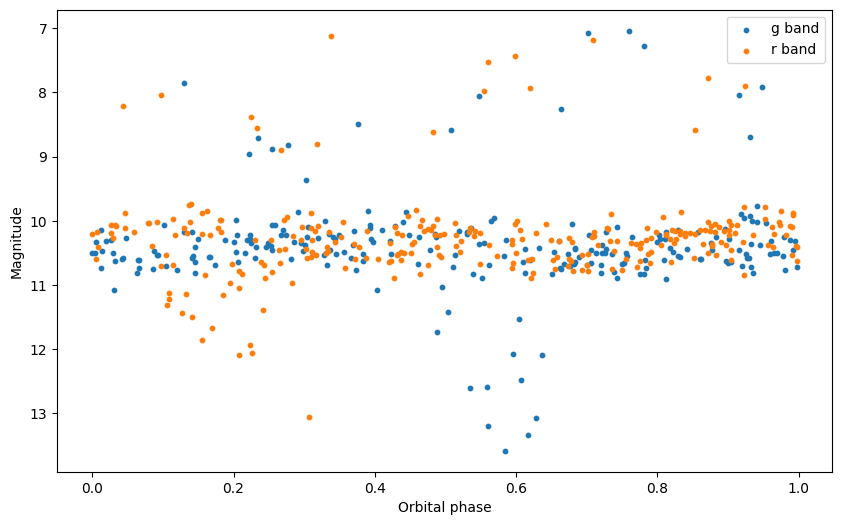

In [121]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_NSV__4618.csv', 'NSV  4618', 17)
phase_folding(0.065769, NS_mag_g, NS_mag_r, NS_mjdzg, NS_mjdzr)

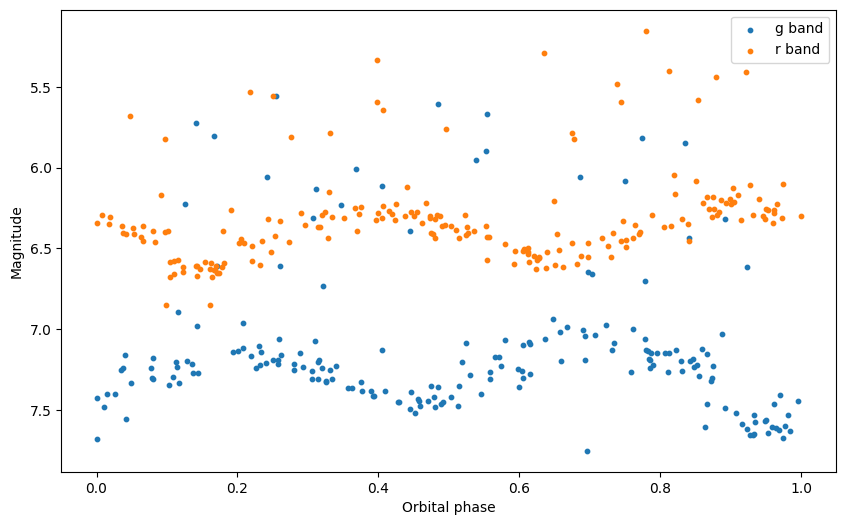

In [53]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_GY_Hya.csv', 'V* GY Hya', 61)
phase_folding(0.347237, mag_g, mag_r, mjd_g, mjd_r)

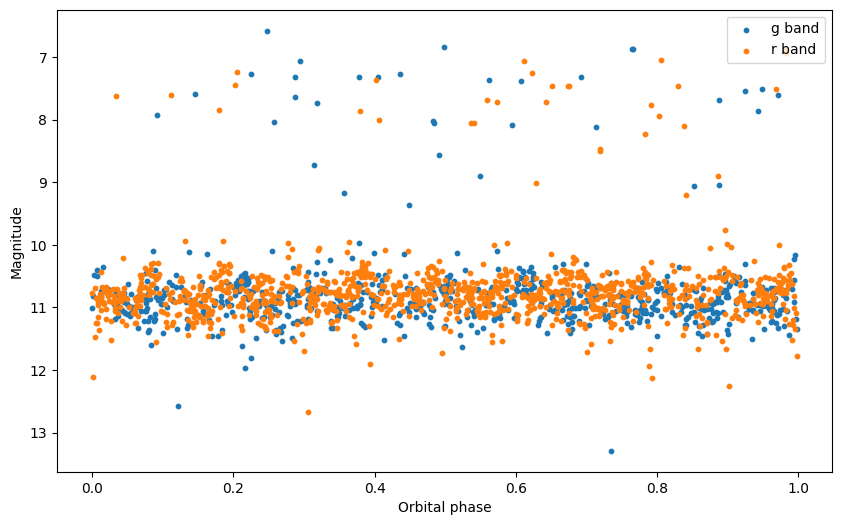

In [48]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_PU_UMa.csv', 'V* PU UMa', 71)
phase_folding(0.77881, mag_g, mag_r, mjd_g, mjd_r)

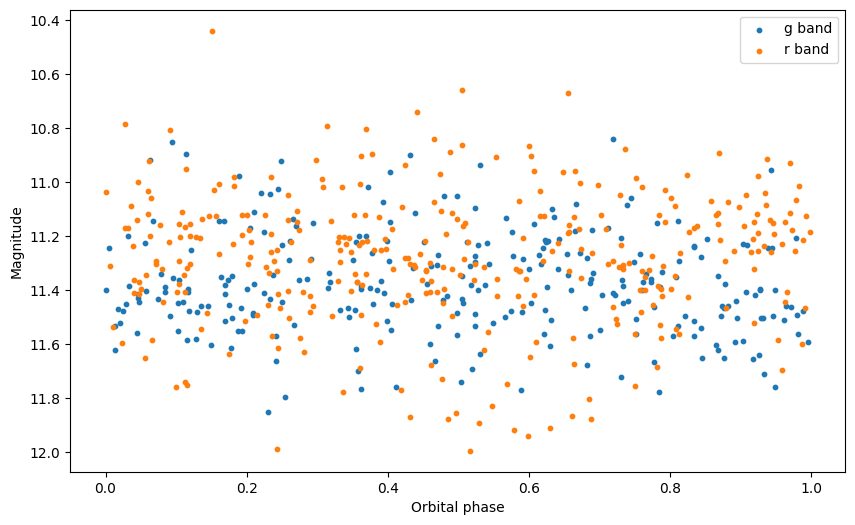

In [49]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_RZ_Leo.csv', 'V* RZ Leo', 81)
phase_folding(0.076038, mag_g, mag_r, mjd_g, mjd_r)

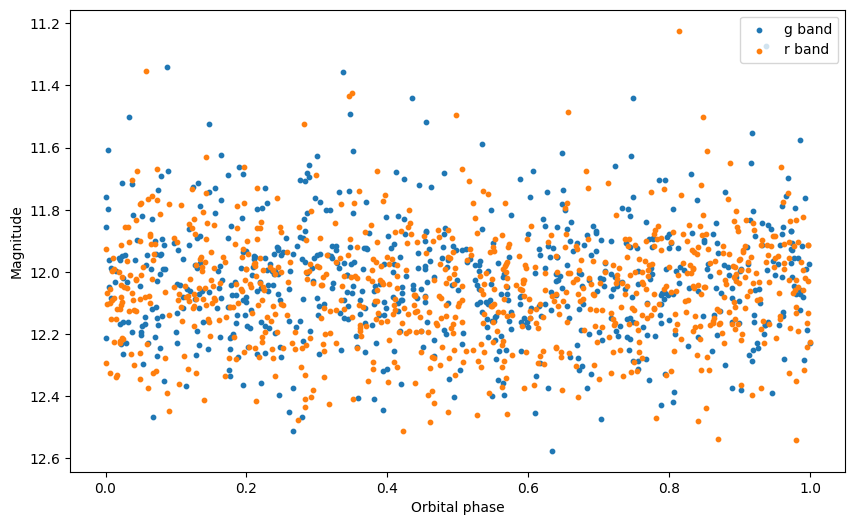

In [50]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_V2176_Cyg.csv', 'V* V2176 Cyg', 95)
phase_folding(0.0554, mag_g, mag_r, mjd_g, mjd_r)

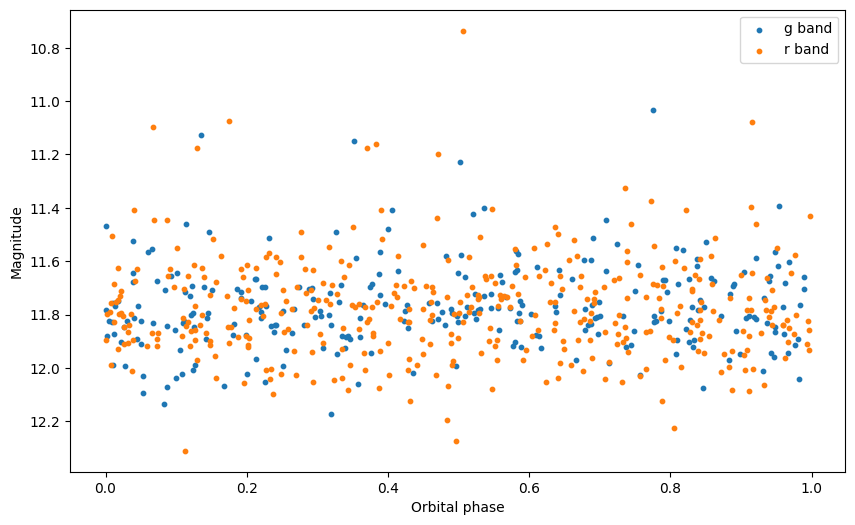

In [51]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_V805_Aur.csv', 'V* V805 Aur', 119)
phase_folding(0.05787, mag_g, mag_r, mjd_g, mjd_r)

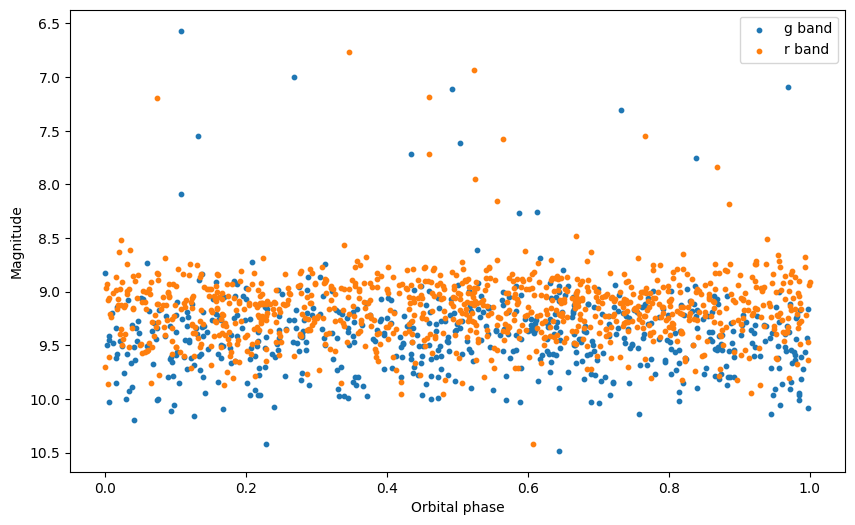

In [52]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_WY_Tri.csv', 'V* WY Tri', 127)
phase_folding(0.0759, mag_g, mag_r, mjd_g, mjd_r)

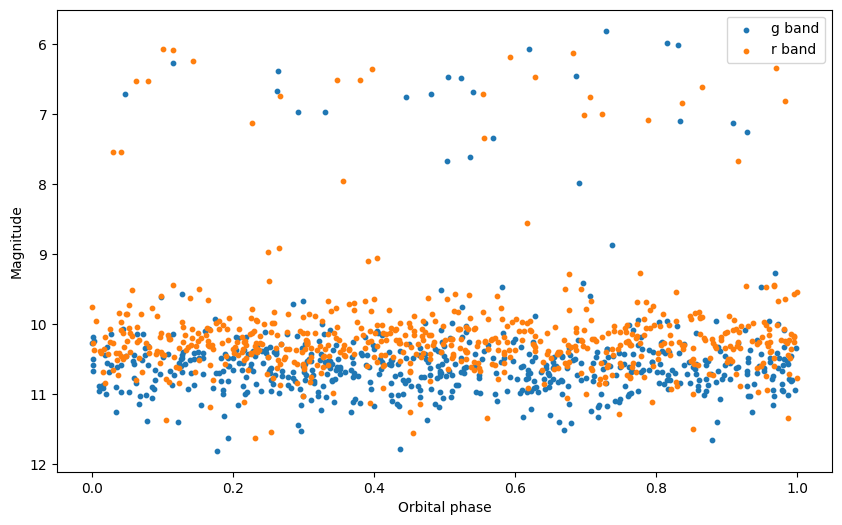

In [56]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_HS_0417+7445.csv', 'HS 0417+7445', 13)
phase_folding(0.07531, mag_g, mag_r, mjd_g, mjd_r)

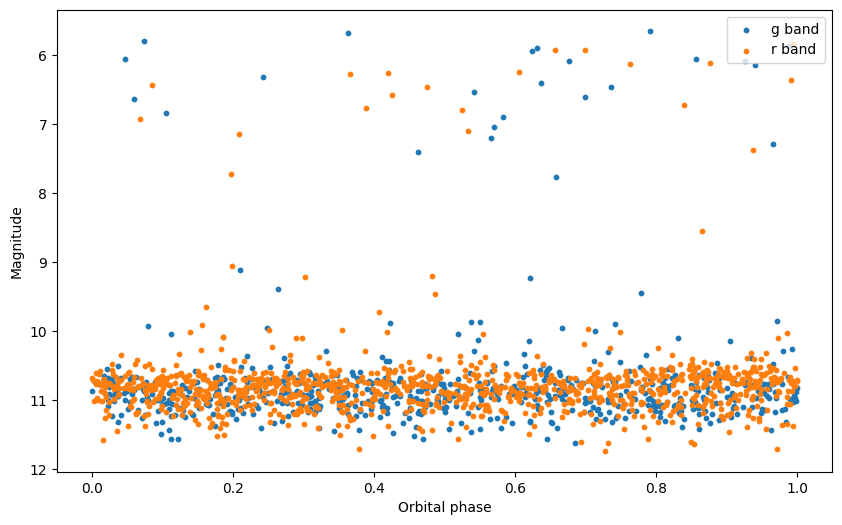

In [57]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_AW_Sge.csv', 'V* AW Sge', 31)
phase_folding(0.072, mag_g, mag_r, mjd_g, mjd_r)

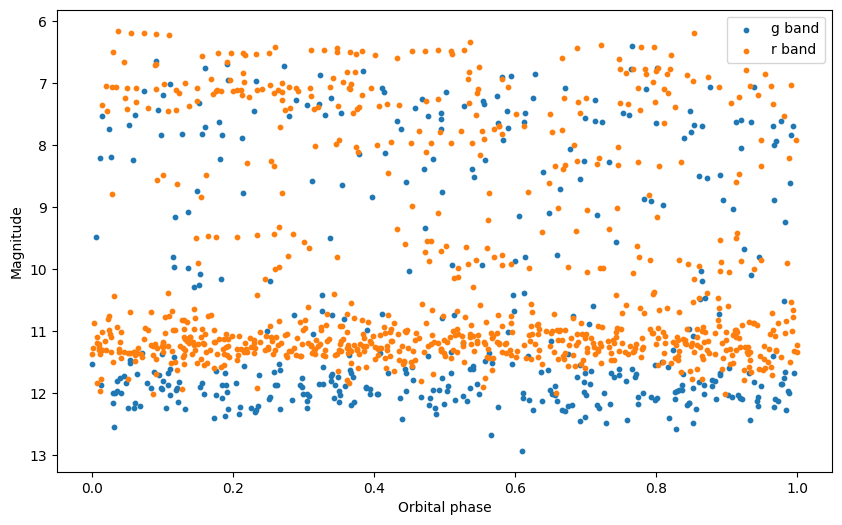

In [58]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_HV_Aur.csv', 'V* HV Aur', 63)
phase_folding(0.0824, mag_g, mag_r, mjd_g, mjd_r)

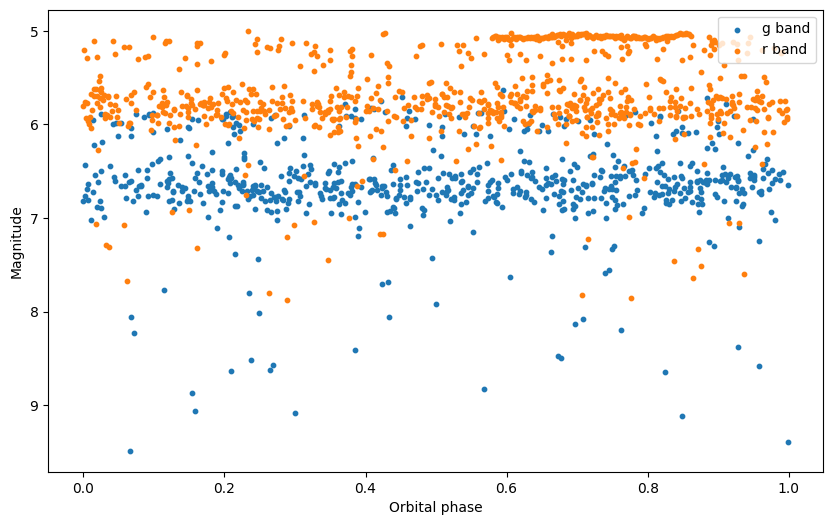

In [122]:
mag_g, mag_r, mjd_g, mjd_r = magnitudes('datos_crudos_ztf/raw_V*_V513_Cas.csv', 'V* V513 Cas', 111)
phase_folding(0.217, mag_g, mag_r, mjd_g, mjd_r)

# Investigate each object

In [112]:
def diagramas(objeto,nombre, item, e, q):
    
    d = pd.read_csv(objeto)
    mag_zg = d['mag_g']
    mjd_zg = d['mjd_g']

    mag_zr = d['mag_r']
    mjd_zr = d['mjd_r']

    df_o = df[df['Name'] == nombre]
    d = df_o['Parallax'][item]

    mag_g = mag_zg - 5*np.log10(1000/d) + 5 
    mag_r = mag_zr - 5*np.log10(1000/d) + 5 

    #mascara
    mask_e = (mag_g > e) & (mag_r > e)
    mask_q = (mag_g < q) & (mag_r < q)

    # Aplicar las mascaras
    qui_g = mag_g[mask_q]
    qui_r = mag_r[mask_q]

    ecl_g = mag_g[mask_e]
    ecl_r = mag_r[mask_e]

    # HR diagram
    hdul = fits.open('gaia-hrd-dr32-200pc.fits')
    data_hr = hdul[1].data
    bp_rp = data_hr['bp_rp']
    mg = data_hr['mg']

    plt.figure(figsize=(9,7))

    # HR
    plt.scatter(bp_rp, mg,alpha=0.05,s=1, color='black',zorder=0)

    gr_q = qui_g - qui_r
    gr_e = ecl_g - ecl_r

    # Objeto
    plt.scatter(gr_q, qui_g, label = 'quiescent')
    plt.scatter(gr_e, ecl_g, label = 'eclipses')
    plt.xlim(-2, 4)
    plt.ylim(4.5, 14)
    
    plt.xlabel('g - r')
    plt.ylabel('Magnitud absoluta')

    plt.gca().invert_yaxis()
    plt.legend(loc = 'upper right')

    plt.save('diagrama_xd.png', )

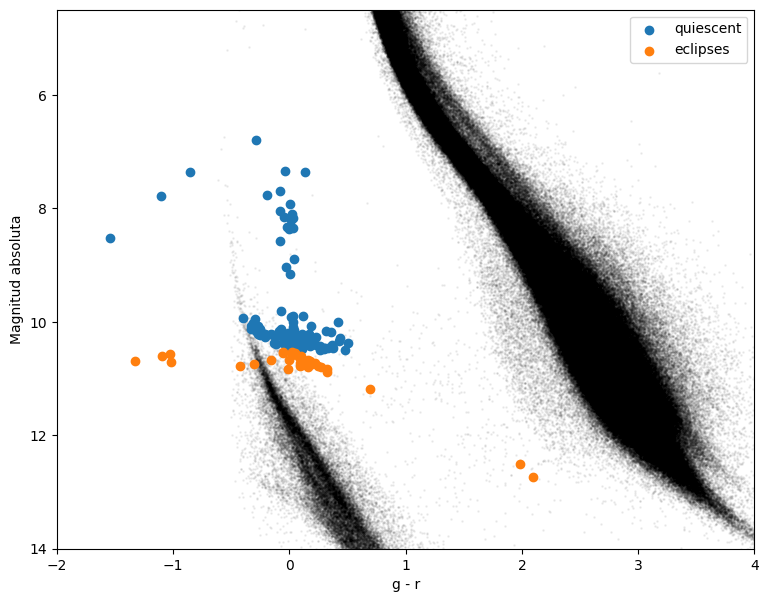

In [126]:
diagramas('datos_filtrados_ztf/match_ASASSN_-13cx.csv', 'ASASSN -13cx', 3, 10.5, 10.5)

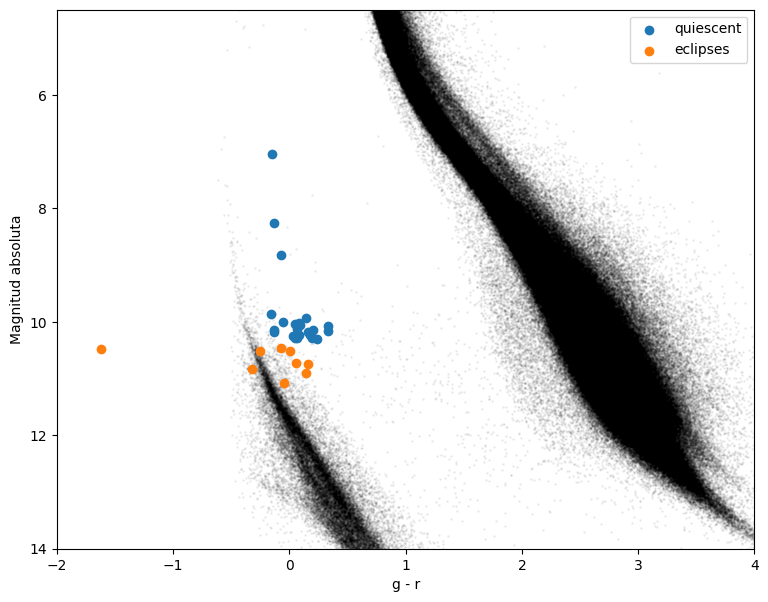

In [129]:
diagramas('datos_filtrados_ztf/match_NSV__4618.csv', 'NSV  4618', 17, 10.4, 10.4)

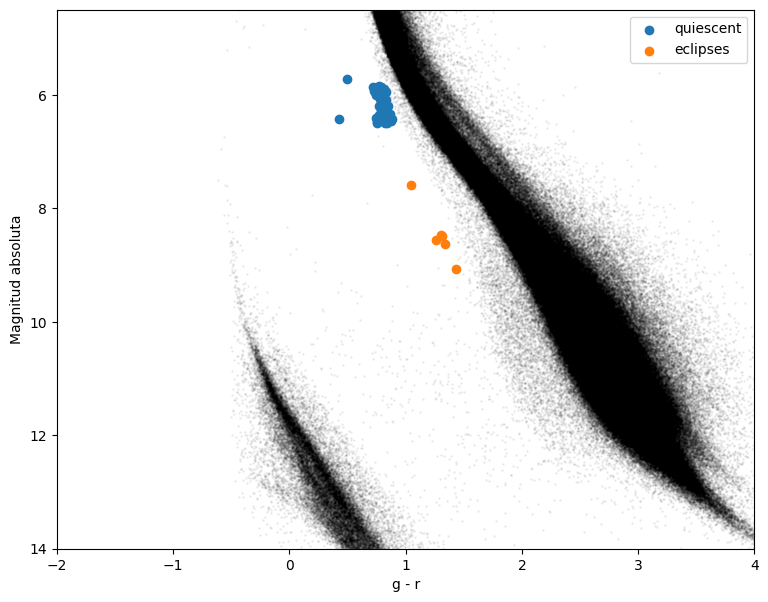

In [130]:
diagramas('datos_filtrados_ztf/match_V*_V513_Cas.csv', 'V* V513 Cas', 111, 6.5, 6.5)

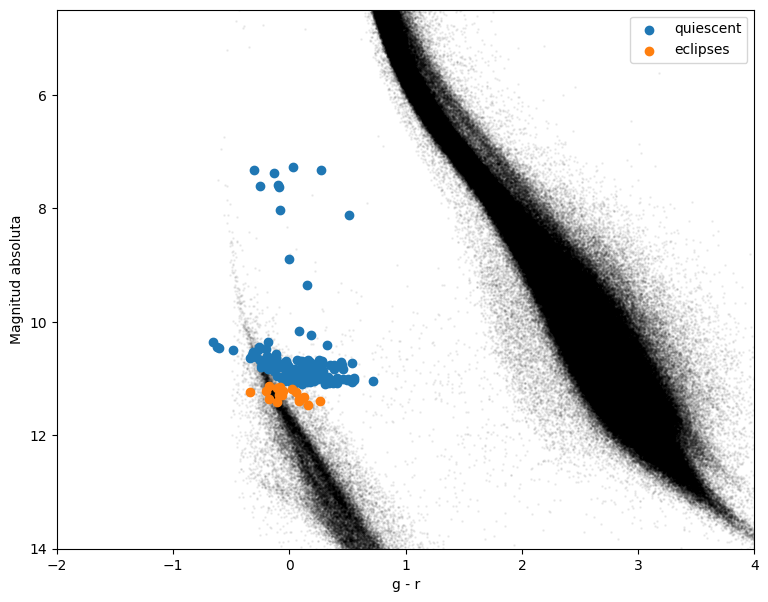

In [132]:
diagramas('datos_filtrados_ztf/match_V*_PU_UMa.csv', 'V* PU UMa', 71, 11.1, 11.1)

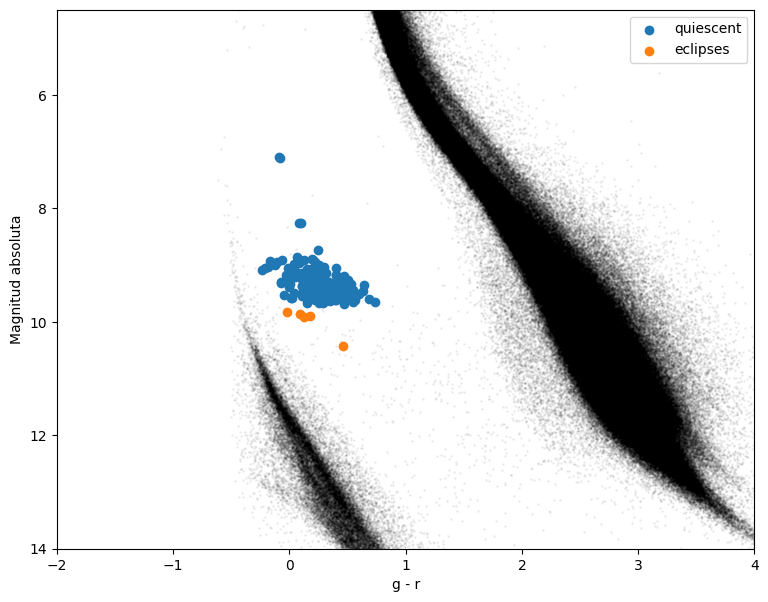

In [125]:
diagramas('datos_filtrados_ztf/match_V*_WY_Tri.csv', 'V* WY Tri', 127, 9.7, 9.7)

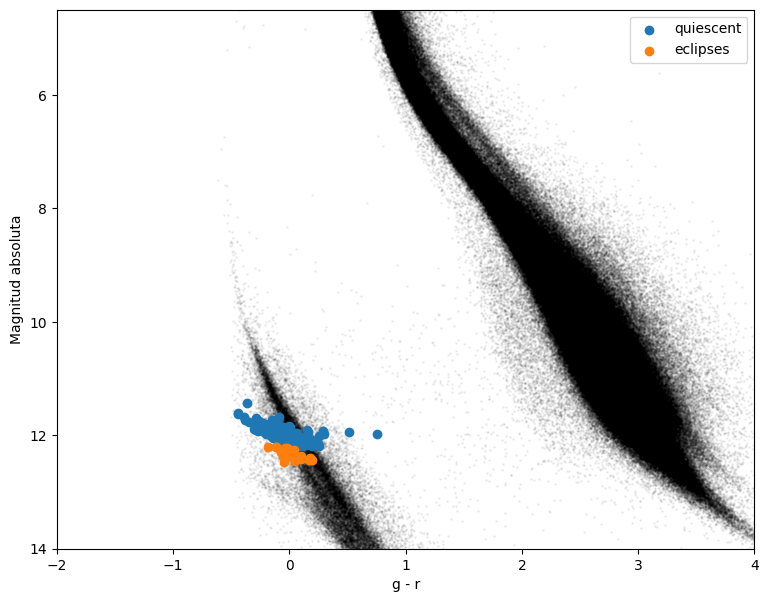

In [124]:
diagramas('datos_filtrados_ztf/match_V*_V2176_Cyg.csv', 'V* V2176 Cyg', 95, 12.2, 12.2)

## Revisar el sample inicial

In [7]:
df = pd.read_csv('Catalogue_DN.csv')
df

,name,source_id,ra,dec,Type1,Type2,Porb,parallax,Incl
0,V* U Gem,674214551557961984,118.771670,22.001222,DN,UG,0.176906,10.704757,NaN
1,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045,NaN
2,V* SS LMi,747774769969350528,158.522601,31.135618,DN,SU,0.056640,0.734795,NaN
3,V* EX Dra,2258357545848389888,271.059771,67.903456,DN,UG,0.209937,4.146697,84.2
4,V* AB Dra,2291308397504739968,297.277042,77.739769,DN,UG,0.152000,2.494294,NaN
...,...,...,...,...,...,...,...,...,...
261,V* QZ Lib,6318149711371454464,234.066746,-8.652398,DN,SU,0.063300,5.022558,NaN
262,V* VY Aqr,6896767366186700416,318.038735,-8.827074,DN,SU,0.063090,7.052574,NaN
263,V* V402 And,2861506395998660096,2.780253,30.543308,DN,SU,0.062100,1.580697,NaN
264,2MASS J00115308-0647392,2443219535337313280,2.971220,-6.794183,DN,UG,0.100281,2.065791,59.0


11.502456 1.056


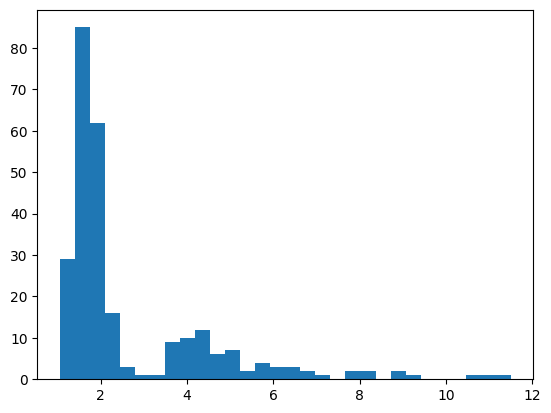

In [19]:
Porb = df['Porb']
plt.hist(Porb*24, bins = 30)
print(max(Porb*24), min(Porb*24))
plt.show()

57 191 18


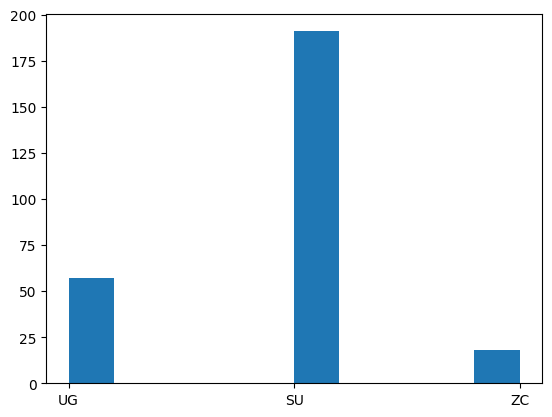

In [26]:
typ = df['Type2']
plt.hist(typ)
print(len(df[df['Type2'] == 'UG']), len(df[df['Type2'] == 'SU']), len(df[df['Type2'] == 'ZC']))

(array([  3., 258.,   2.,   1.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.]),
 array([ -4561.83343363,  -1102.37804894,   2357.07733574,   5816.53272042,
          9275.9881051 ,  12735.44348978,  16194.89887446,  19654.35425914,
         23113.80964382,  26573.2650285 ,  30032.72041318,  33492.17579786,
         36951.63118254,  40411.08656722,  43870.5419519 ,  47329.99733658,
         50789.45272127,  54248.90810595,  57708.36349063,  61167.81887531,
         64627.27425999,  68086.72964467,  71546.18502935,  75005.64041403,
         78465.09579871,  81924.55118339,  85384.00656807,  88843.46195275,
         92302.91733743,  95762.37272211,  99221.82810679, 102681.28349148,
        106140.73887616, 109600.19426084, 113059.6

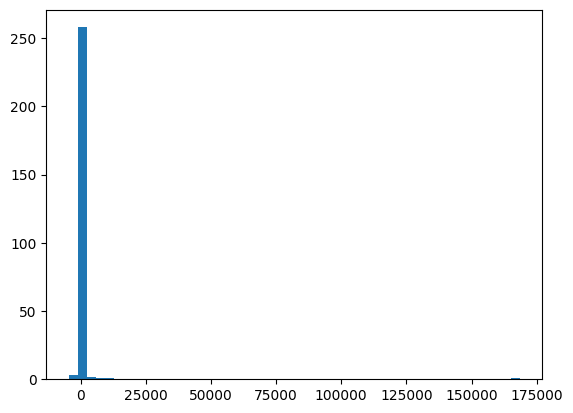

In [31]:
parallax = df['parallax']
dist = 1000/parallax


In [37]:
i = df['Incl']
print(i.count())

28


In [6]:
df2 = pd.read_csv('DN_seleccionadas.csv')
error_para = df2['Parallax_error']
error_d = 1000/error_para

for i in error_d:
    print(i)

10080.645161290324
10080.645161290324
7468.259895444362
7468.259895444362
9107.468123861567
9107.468123861567
3407.155025553663
3407.155025553663
3465.0034650034645
3465.0034650034645
6752.19446320054
6752.19446320054
10741.138560687432
10741.138560687432
3625.8158085569253
3625.8158085569253
15105.740181268884
15105.740181268884
5837.711617046118
5837.711617046118
20491.803278688523
20491.803278688523
15873.015873015873
15873.015873015873
6510.416666666667
6510.416666666667
11098.779134295228
11098.779134295228
15015.015015015013
15015.015015015013
4139.072847682119
4139.072847682119
15723.270440251572
15723.270440251572
22988.505747126437
22988.505747126437
38759.68992248062
38759.68992248062
56818.181818181816
56818.181818181816
15337.423312883437
15337.423312883437
3720.2380952380954
3720.2380952380954
8532.423208191127
8532.423208191127
18975.332068311196
18975.332068311196
29940.119760479043
29940.119760479043
15384.615384615385
15384.615384615385
2837.684449489217
2837.684449489